## 0. Instalacja i importy

In [24]:
!pip install -q torch torchvision opencv-python-headless matplotlib tensorflow-datasets torchcodec importlib_resources

In [25]:
import os, urllib.request, time, json
import numpy as np
import cv2
import torch
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Dataset, Subset
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
from collections import Counter
import importlib_resources

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| OpenCV:", cv2.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cu130 | OpenCV: 4.14.0 | urządzenie: cuda


## 1. Zbiór danych i mostek TFDS

In [26]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow_datasets as tfds

DS_NAME = "rock_paper_scissors"
(ds_train_tf, ds_test_tf), info = tfds.load(
    DS_NAME, split=["train", "test"], as_supervised=True, with_info=True,
    data_dir="tfds_data")
CLASSES_TFDS = info.features["label"].names
print("Zbiór:", info.name, "| wersja:", info.version, "| rozmiar pobierania:", info.download_size)
print("Klasy (TFDS, alfabetycznie):", CLASSES_TFDS)
print("Przykłady:", {s: info.splits[s].num_examples for s in ("train", "test")})
print("Kształt obrazu:", info.features["image"].shape, "| typ:", info.features["image"].np_dtype)

Zbiór: rock_paper_scissors | wersja: 3.0.0 | rozmiar pobierania: 219.53 MiB
Klasy (TFDS, alfabetycznie): ['rock', 'paper', 'scissors']
Przykłady: {'train': 2520, 'test': 372}
Kształt obrazu: (300, 300, 3) | typ: <class 'numpy.uint8'>


In [27]:
class TFDSToTorchDataset(Dataset):

    def __init__(self, tfds_split, classes, transform=None):
        self._examples = [(img.numpy(), int(lbl)) for img, lbl in tfds_split]
        self.classes = list(classes)
        self.class_to_idx = {c: i for i, c in enumerate(self.classes)}
        self.transform = transform

    def __len__(self):
        return len(self._examples)

    def __getitem__(self, i):
        img_np, label = self._examples[i]
        img = Image.fromarray(img_np)
        if self.transform is not None:
            img = self.transform(img)
        return img, label

rps_ds = TFDSToTorchDataset(ds_train_tf, CLASSES_TFDS)
print("Mostek na splitcie 'train':", len(rps_ds), "przykładów | klasy:", rps_ds.classes)
print("class_to_idx (z TFDS):", rps_ds.class_to_idx)
img0, lab0 = rps_ds[0]
print("Przykład 0:", type(img0).__name__, img0.size, "| etykieta:", lab0, "->", rps_ds.classes[lab0])
print("Balans klas w splitcie 'train':", Counter(lab for _, lab in rps_ds._examples))

Mostek na splitcie 'train': 2520 przykładów | klasy: ['rock', 'paper', 'scissors']
class_to_idx (z TFDS): {'rock': 0, 'paper': 1, 'scissors': 2}
Przykład 0: Image (300, 300) | etykieta: 2 -> scissors
Balans klas w splitcie 'train': Counter({2: 840, 0: 840, 1: 840})


In [28]:
ROOT = "dane"
DIR_NAMES = {"paper": "papier", "rock": "kamien", "scissors": "nozyce"}

g = torch.Generator().manual_seed(42)
VAL_FRAC = 0.2
valid_members = {}
for c, n in Counter(lab for _, lab in rps_ds._examples).items():
    perm = torch.randperm(n, generator=g).tolist()
    valid_members[c] = set(perm[:int(VAL_FRAC * n)])

os.makedirs(f"{ROOT}/train", exist_ok=True)
os.makedirs(f"{ROOT}/valid", exist_ok=True)
seen = Counter()
for i in range(len(rps_ds)):
    img_pil, label = rps_ds[i]
    c = label
    part = "valid" if seen[c] in valid_members[c] else "train"
    seen[c] += 1
    os.makedirs(f"{ROOT}/{part}/{DIR_NAMES[CLASSES_TFDS[c]]}", exist_ok=True)
    img_pil.save(f"{ROOT}/{part}/{DIR_NAMES[CLASSES_TFDS[c]]}/{DIR_NAMES[CLASSES_TFDS[c]]}_{seen[c]-1:04d}.jpg", quality=95)

print("Zapisano układ ImageFolder w katalogu:", ROOT)
for part in ("train", "valid"):
    for c in sorted(os.listdir(f"{ROOT}/{part}")):
        print(f"  {part}/{c}: {len(os.listdir(os.path.join(ROOT, part, c)))} obrazów")
print("Split 'test' TFDS (372 obrazów) zostaje jako niezależna kontrola — nieużywany w tym sprawozdaniu.")

Zapisano układ ImageFolder w katalogu: dane
  train/kamien: 672 obrazów
  train/nozyce: 672 obrazów
  train/papier: 672 obrazów
  valid/kamien: 168 obrazów
  valid/nozyce: 168 obrazów
  valid/papier: 168 obrazów
Split 'test' TFDS (372 obrazów) zostaje jako niezależna kontrola — nieużywany w tym sprawozdaniu.


## 2. Transformacje: potok ewaluacyjny i treningowy


In [29]:
eval_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])

train_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3),
])

## 3. ImageFolder i DataLoader

In [30]:
train_ds = datasets.ImageFolder(root="dane/train", transform=train_tf)
val_ds   = datasets.ImageFolder(root="dane/valid", transform=eval_tf)

assert train_ds.class_to_idx == val_ds.class_to_idx, "rozne class_to_idx w train i valid!"
print("Klasy:", train_ds.classes, "-> indeksy:", train_ds.class_to_idx)
print("Liczba przykładów: train =", len(train_ds), "| valid =", len(val_ds))

train_dl = DataLoader(train_ds, batch_size=16, shuffle=True,  num_workers=0, drop_last=True, pin_memory=True)
val_dl   = DataLoader(val_ds,   batch_size=16, shuffle=False, num_workers=0)
print("Liczba paczek: train =", len(train_dl), "| valid =", len(val_dl))

with open("class_to_idx.json", "w", encoding="utf-8") as f:
    json.dump(train_ds.class_to_idx, f, ensure_ascii=False, indent=2)
print("Zapisano mapowanie class_to_idx -> class_to_idx.json")

print("Balans train (Counter(ds.targets)):", Counter(train_ds.targets))
print("Balans valid (Counter(ds.targets)):", Counter(val_ds.targets))

Klasy: ['kamien', 'nozyce', 'papier'] -> indeksy: {'kamien': 0, 'nozyce': 1, 'papier': 2}
Liczba przykładów: train = 2016 | valid = 504
Liczba paczek: train = 126 | valid = 32
Zapisano mapowanie class_to_idx -> class_to_idx.json
Balans train (Counter(ds.targets)): Counter({0: 672, 1: 672, 2: 672})
Balans valid (Counter(ds.targets)): Counter({0: 168, 1: 168, 2: 168})


## 4. Audyt jednej paczki

Kształt: torch.Size([16, 3, 64, 64]) zakres: -1.0 1.0
Typ: torch.float32
Etykiety: [2, 2, 0, 1, 2, 2, 1, 2, 0, 1, 2, 0, 1, 0, 2, 0]
Licznik klas: Counter({2: 7, 0: 5, 1: 4})


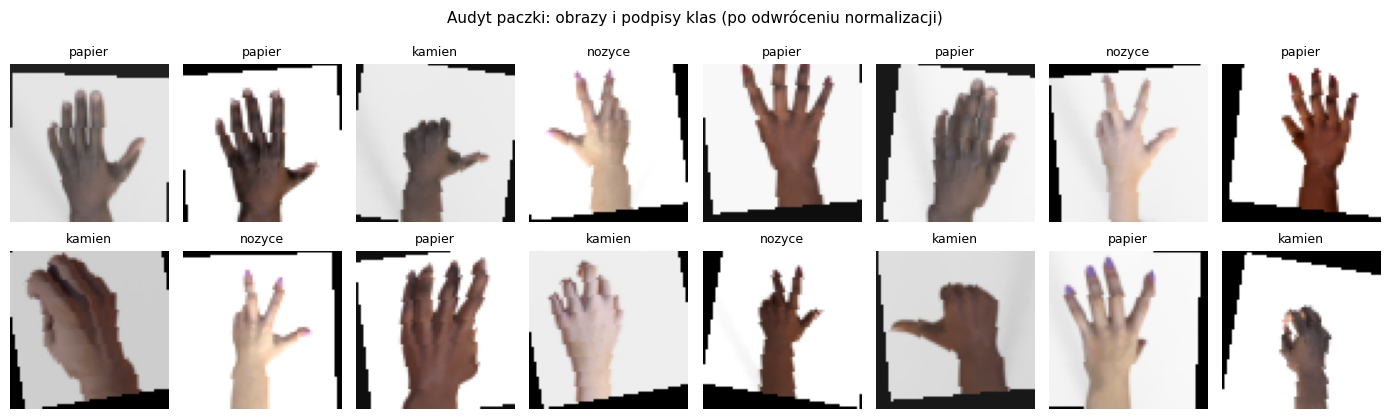

In [31]:
os.makedirs("fig", exist_ok=True)

xb, yb = next(iter(train_dl))
print("Kształt:", xb.shape, "zakres:", xb.min().item(), xb.max().item())
print("Typ:", xb.dtype)
print("Etykiety:", yb.tolist())
print("Licznik klas:", Counter(yb.tolist()))

fig, axes = plt.subplots(2, 8, figsize=(14, 4.4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow((img * 0.5 + 0.5).permute(1, 2, 0).numpy())
    ax.set_title(train_ds.classes[lb.item()], fontsize=9)
    ax.axis("off")
fig.suptitle("Audyt paczki: obrazy i podpisy klas (po odwróceniu normalizacji)", fontsize=11)
plt.tight_layout(); plt.savefig("fig/audyt_paczki.png", dpi=120); plt.show()

## 5. Podgląd augmentacji

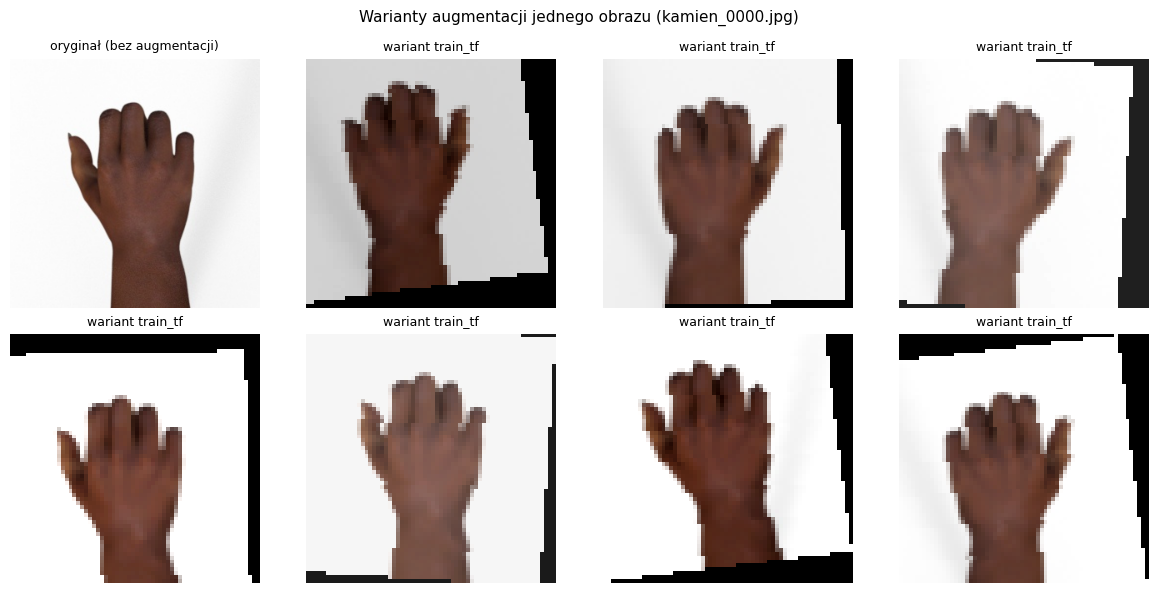

In [32]:
raw = Image.open(train_ds.samples[0][0]).convert("RGB")
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
axes[0, 0].imshow(raw)
axes[0, 0].set_title("oryginał (bez augmentacji)", fontsize=9)
for ax in axes.flat[1:]:
    aug = train_tf(raw)
    ax.imshow((aug * 0.5 + 0.5).permute(1, 2, 0).numpy())
    ax.set_title("wariant train_tf", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle(f"Warianty augmentacji jednego obrazu ({os.path.basename(train_ds.samples[0][0])})", fontsize=11)
plt.tight_layout(); plt.savefig("fig/augmentacja.png", dpi=120); plt.show()

## 6. Statystyki zbioru

In [33]:
print(f"Liczba klas: {len(train_ds.classes)}")
print(f"Rozmiar obrazu po transformacji: [3, 64, 64] (CHW, float32, zakres -1..1)")
print(f"Rozmiar paczki z DataLoader: [16, 3, 64, 64]  (N, C, H, W)")
print(f"Paczek: train {len(train_dl)} x 16 = {len(train_dl)*16} obrazów | valid {len(val_dl)} paczek, ostatnia z {len(val_ds) - (len(val_dl)-1)*16} obrazami")
print()
print("| część | klasa | liczba obrazów |")
print("|---|---|---|")
for part_name, ds_ in (("train", train_ds), ("valid", val_ds)):
    cnt = Counter(ds_.targets)
    for cls_name, cls_idx in ds_.class_to_idx.items():
        print(f"| {part_name} | {cls_name} | {cnt[cls_idx]} |")
print()
print("class_to_idx (zapisane do class_to_idx.json):", train_ds.class_to_idx)
print("Mapowanie TFDS (alfabetycznie):", {c: i for i, c in enumerate(CLASSES_TFDS)})

Liczba klas: 3
Rozmiar obrazu po transformacji: [3, 64, 64] (CHW, float32, zakres -1..1)
Rozmiar paczki z DataLoader: [16, 3, 64, 64]  (N, C, H, W)
Paczek: train 126 x 16 = 2016 obrazów | valid 32 paczek, ostatnia z 8 obrazami

| część | klasa | liczba obrazów |
|---|---|---|
| train | kamien | 672 |
| train | nozyce | 672 |
| train | papier | 672 |
| valid | kamien | 168 |
| valid | nozyce | 168 |
| valid | papier | 168 |

class_to_idx (zapisane do class_to_idx.json): {'kamien': 0, 'nozyce': 1, 'papier': 2}
Mapowanie TFDS (alfabetycznie): {'rock': 0, 'paper': 1, 'scissors': 2}


## 7. Weryfikacja potoku

In [34]:
from torch import nn

torch.manual_seed(0)
model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(3 * 64 * 64, 128), nn.ReLU(),
    nn.Linear(128, len(train_ds.classes)),
).to(device)
loss_fn = nn.CrossEntropyLoss()

xb, yb = next(iter(train_dl))
xb, yb = xb.to(device), yb.to(device)

with torch.no_grad():
    loss0 = loss_fn(model(xb), yb).item()
print(f"Strata startowa: {loss0:.3f}  |  oczekiwane ~ln(3) = {np.log(3):.3f}")

opt = torch.optim.Adam(model.parameters(), lr=1e-3)
for step in range(100):
    loss = loss_fn(model(xb), yb)
    opt.zero_grad(); loss.backward(); opt.step()
print(f"Strata po 100 krokach na jednej paczce: {loss.item():.4f}  |  oczekiwane: bliskie 0")

Strata startowa: 1.165  |  oczekiwane ~ln(3) = 1.099
Strata po 100 krokach na jednej paczce: 0.0001  |  oczekiwane: bliskie 0


In [35]:
def make_image(kind, size=64):
    bg = tuple(int(x) for x in np.random.randint(20, 80, size=3))
    img = Image.new("RGB", (size, size), bg)
    d = ImageDraw.Draw(img)
    color = tuple(int(x) for x in np.random.randint(120, 255, size=3))
    m = np.random.randint(6, 14)
    box = [m, m, size - m, size - m]
    d.ellipse(box, fill=color) if kind == "kolo" else d.rectangle(box, fill=color)
    return img

ROOT_DEMO = "dane_demo"
N_TRAIN_DEMO, N_VALID_DEMO = 48, 12
for c in ("kolo", "kwadrat"):
    os.makedirs(f"{ROOT_DEMO}/train/{c}", exist_ok=True)
    os.makedirs(f"{ROOT_DEMO}/valid/{c}", exist_ok=True)
    for i in range(N_TRAIN_DEMO):
        make_image(c).save(f"{ROOT_DEMO}/train/{c}/{c}_{i:03d}.jpg")
    for i in range(N_VALID_DEMO):
        make_image(c).save(f"{ROOT_DEMO}/valid/{c}/{c}_{i:03d}.jpg")
print("Utworzono zbior kontrolny:", ROOT_DEMO)

demo_train_ds = datasets.ImageFolder(f"{ROOT_DEMO}/train", transform=train_tf)
demo_val_ds   = datasets.ImageFolder(f"{ROOT_DEMO}/valid", transform=eval_tf)
print("Klasy:", demo_train_ds.classes, "->", demo_train_ds.class_to_idx,
      "| balans:", Counter(demo_train_ds.targets), Counter(demo_val_ds.targets))
demo_train_dl = DataLoader(demo_train_ds, batch_size=16, shuffle=True,  num_workers=0, drop_last=True)
demo_val_dl   = DataLoader(demo_val_ds,   batch_size=16, shuffle=False, num_workers=0)

def smoke_train(train_dl_, val_dl_, n_classes, epochs=5, title=""):
    torch.manual_seed(0)
    m = nn.Sequential(nn.Flatten(), nn.Linear(3 * 64 * 64, 128), nn.ReLU(),
                      nn.Linear(128, n_classes)).to(device)
    lf = nn.CrossEntropyLoss()
    op = torch.optim.Adam(m.parameters(), lr=1e-3)
    for epoch in range(epochs):
        m.train(); total = 0
        for xb_, yb_ in train_dl_:
            loss = lf(m(xb_.to(device)), yb_.to(device))
            op.zero_grad(); loss.backward(); op.step()
            total += loss.item() * len(yb_)
        m.eval(); correct = 0
        with torch.no_grad():
            for xb_, yb_ in val_dl_:
                correct += (m(xb_.to(device)).argmax(1) == yb_.to(device)).sum().item()
        print(f"  {title} epoka {epoch+1}: train loss {total/len(train_dl_.dataset):.3f} | val acc {correct/len(val_dl_.dataset):.2f}")

print("Test dymny na dane_demo (kontrola, wstęp sekcja 9 krok 4):")
smoke_train(demo_train_dl, demo_val_dl, 2, title="demo")
print("Test dymny na rock_paper_scissors:")
smoke_train(train_dl, val_dl, len(train_ds.classes), title="RPS")

Utworzono zbior kontrolny: dane_demo
Klasy: ['kolo', 'kwadrat'] -> {'kolo': 0, 'kwadrat': 1} | balans: Counter({0: 48, 1: 48}) Counter({0: 12, 1: 12})
Test dymny na dane_demo (kontrola, wstęp sekcja 9 krok 4):
  demo epoka 1: train loss 1.799 | val acc 0.71
  demo epoka 2: train loss 0.774 | val acc 0.92
  demo epoka 3: train loss 0.516 | val acc 0.92
  demo epoka 4: train loss 0.356 | val acc 1.00
  demo epoka 5: train loss 0.138 | val acc 1.00
Test dymny na rock_paper_scissors:
  RPS epoka 1: train loss 1.046 | val acc 0.78
  RPS epoka 2: train loss 0.733 | val acc 0.70
  RPS epoka 3: train loss 0.523 | val acc 0.72
  RPS epoka 4: train loss 0.481 | val acc 0.61
  RPS epoka 5: train loss 0.458 | val acc 0.94


## 8. Wideo jako sekwencja klatek

In [36]:
VIDEO = "demo.avi"
H, W, FPS, N_FRAMES = 120, 160, 20, 60
vw = cv2.VideoWriter(VIDEO, cv2.VideoWriter_fourcc(*"MJPG"), FPS, (W, H))
for t in range(N_FRAMES):
    frame = np.full((H, W, 3), 30, np.uint8)
    cx = int(20 + (W - 40) * t / (N_FRAMES - 1))
    cv2.circle(frame, (cx, H // 2), 15, (0, 140, 255), -1)
    vw.write(frame)
vw.release()
print("Zapisano film:", VIDEO)

cap = cv2.VideoCapture(VIDEO)
assert cap.isOpened(), "nie udalo sie otworzyc pliku - sprawdz cap.isOpened() (wstęp, 6.4)"
fps_meta = cap.get(cv2.CAP_PROP_FPS)
n_meta = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
cap.release()
print(f"FPS: {fps_meta} | klatki (z metadanych): {n_meta} | czas trwania: {n_meta / fps_meta:.2f} s")

Zapisano film: demo.avi
FPS: 20.0 | klatki (z metadanych): 60 | czas trwania: 3.00 s


FPS: 20.0 | klatek odczytanych (faktycznie): 60 | pobrano co 10. -> 6 klatek
Odstęp czasowy próbek: every/FPS = 10/20 = 0.50 s  (wstęp, 6.2)


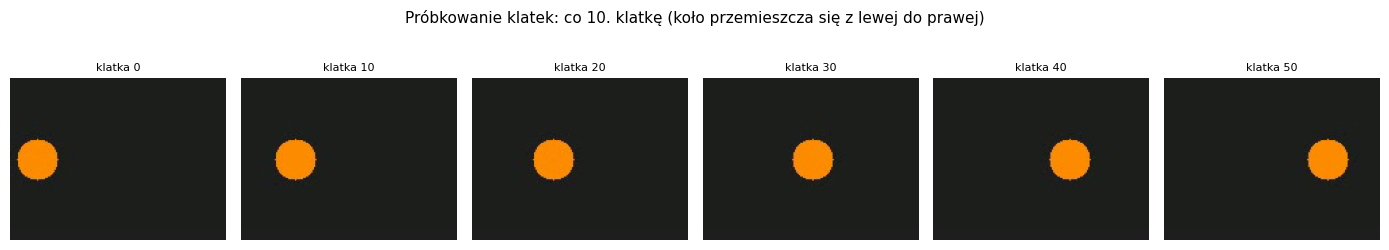

every | klatek | odstęp [s] | FPS/every = próbek na sekundę
    1 |     60 |      0.05 | 20.0
    5 |     12 |      0.25 | 4.0
   10 |      6 |      0.50 | 2.0
   30 |      2 |      1.50 | 0.7
Mniejsze every -> więcej obrazów, ale bardzo podobnych do siebie;
większe every -> mniej obrazów, za to bardziej zróżnicowanych (wstęp, 6.2).


In [37]:
def sample_frames(path, every=10):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        return [], 0.0, 0
    fps = cap.get(cv2.CAP_PROP_FPS)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frames, i = [], 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if i % every == 0:
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        i += 1
    cap.release()
    return frames, fps, i

frames, fps, total_read = sample_frames(VIDEO, every=10)
print(f"FPS: {fps} | klatek odczytanych (faktycznie): {total_read} | pobrano co 10. -> {len(frames)} klatek")
print(f"Odstęp czasowy próbek: every/FPS = 10/{fps:.0f} = {10/fps:.2f} s  (wstęp, 6.2)")

fig, axes = plt.subplots(1, len(frames), figsize=(14, 2.8))
for ax, fr, idx in zip(axes, frames, range(len(frames))):
    ax.imshow(fr)
    ax.set_title(f"klatka {idx*10}", fontsize=8)
    ax.axis("off")
fig.suptitle("Próbkowanie klatek: co 10. klatkę (koło przemieszcza się z lewej do prawej)", fontsize=11)
plt.tight_layout(); plt.savefig("fig/klatki_every10.png", dpi=120); plt.show()

print("every | klatek | odstęp [s] | FPS/every = próbek na sekundę")
for every in (1, 5, 10, 30):
    frs, _, _ = sample_frames(VIDEO, every=every)
    print(f"{every:>5} | {len(frs):>6} | {every/fps:>9.2f} | {fps/every:.1f}")
print("Mniejsze every -> więcej obrazów, ale bardzo podobnych do siebie;")
print("większe every -> mniej obrazów, za to bardziej zróżnicowanych (wstęp, 6.2).")

Kształt i typ bez zmian: (120, 160, 3) uint8 -> (120, 160, 3) uint8
Piksel w środku koła:
  BGR (jak zwraca OpenCV): [0, 140, 253]
  RGB (po cvtColor):       [253, 140, 0]
RGB == BGR z zamienioną kolejnością kanałów? True


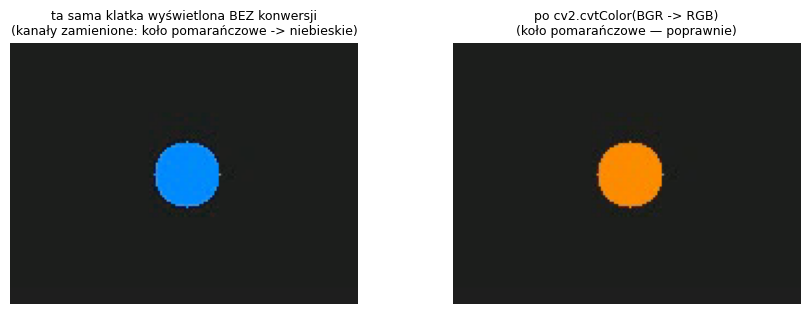

In [38]:
cap = cv2.VideoCapture(VIDEO)
cap.set(cv2.CAP_PROP_POS_FRAMES, 30)
ok, frame_bgr = cap.read()
cap.release()
assert ok, "brak klatki"

frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
cy = frame_bgr.shape[0] // 2
cx = int(20 + (W - 40) * 30 / (N_FRAMES - 1))
print("Kształt i typ bez zmian:", frame_bgr.shape, frame_bgr.dtype, "->", frame_rgb.shape, frame_rgb.dtype)
print("Piksel w środku koła:")
print("  BGR (jak zwraca OpenCV):", frame_bgr[cy, cx].tolist())
print("  RGB (po cvtColor):      ", frame_rgb[cy, cx].tolist())
print("RGB == BGR z zamienioną kolejnością kanałów?", bool((frame_rgb == frame_bgr[:, :, ::-1]).all()))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].imshow(frame_bgr)
axes[0].set_title("ta sama klatka wyświetlona BEZ konwersji\n(kanały zamienione: koło pomarańczowe -> niebieskie)", fontsize=9)
axes[1].imshow(frame_rgb)
axes[1].set_title("po cv2.cvtColor(BGR -> RGB)\n(koło pomarańczowe — poprawnie)", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout(); plt.savefig("fig/bgr_rgb.png", dpi=120); plt.show()

In [39]:
import time

t0 = time.perf_counter()
frs, fps2, total2 = sample_frames(VIDEO, every=10)
t_cv2 = time.perf_counter() - t0
print(f"cv2.VideoCapture: {len(frs)} klatek co 10. | wynik: list[np.ndarray [H,W,3]] uint8, BGR->RGB | czas: {t_cv2*1000:.1f} ms")

try:
    from torchcodec.decoders import VideoDecoder
    t0 = time.perf_counter()
    dec = VideoDecoder(VIDEO)
    frames_tc = dec.get_frames_at(indices=[0, 10, 20, 30, 40, 50])
    t_tc = time.perf_counter() - t0
    print(f"TorchCodec:       kształt {tuple(frames_tc.data.shape)}, typ {frames_tc.data.dtype}, kanały RGB | czas: {t_tc*1000:.1f} ms")
except Exception as e:
    print("TorchCodec niedostępny w tym środowisku:", type(e).__name__, "-", str(e)[:140])

cv2.VideoCapture: 6 klatek co 10. | wynik: list[np.ndarray [H,W,3]] uint8, BGR->RGB | czas: 10.4 ms
TorchCodec:       kształt (6, 3, 120, 160), typ torch.uint8, kanały RGB | czas: 2.4 ms
